# Calcoli dell’audit Olist

Riconcilio i risultati verificati con i dati originali. [Rapporto inglese](../README.md) | [Rapporto italiano](../README.it.md). Dati: [Olist su Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), CC BY-NC-SA 4.0. Associazioni e ipotesi finanziarie non sono risparmi causali.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
from src.data import load_orders
from src.risk import FEATURES
from src.diagnostics import review_diagnostics, repeat_purchases
from src.analysis import financial_scenario
reports = root / 'reports'
summary = json.loads((reports / 'summary.json').read_text())
frame, quality = load_orders()
assert len(frame) == 96470
assert frame.order_id.is_unique
assert 'customer_unique_id' in frame
assert len(FEATURES) == 19
quality

{'raw_orders': 99441,
 'raw_reviews': 99224,
 'extra_reviews': 551,
 'without_items': 775,
 'without_score': 768,
 'statuses': {'delivered': 96478,
  'shipped': 1107,
  'canceled': 625,
  'unavailable': 609,
  'invoiced': 314,
  'processing': 301,
  'created': 5,
  'approved': 2},
 'eligible_delivered': 96470,
 'excluded': 2971,
 'multi_seller': 1275,
 'reviews_before_delivery': 4768,
 'purchase_min': '2016-09-15 12:16:38',
 'purchase_max': '2018-08-29 15:00:37'}

## Tempi del questionario e testo mancante

La creazione è l’invito, non la risposta. I timestamp a mezzanotte richiedono il confronto per giorno di calendario. I temi descrivono solo recensioni con testo.

In [2]:
diagnostics = review_diagnostics(frame)
assert diagnostics['without_text'] == 55224
for filename in ['review_timing.csv', 'text_coverage.csv', 'score_by_text.csv']:
    display(pd.read_csv(reports / filename))

,population,review_time,definition,before_delivery,orders,share,missing_review_time,missing_delivery_time
0,all_late,creation,timestamp,5334,6534,0.816345,153,0
1,all_late,creation,calendar_day,4753,6534,0.727426,153,0
2,all_late,answer,timestamp,4476,6534,0.685032,153,0
3,all_late,answer,calendar_day,4089,6534,0.625803,153,0
4,reviewed_late,creation,timestamp,5334,6381,0.835919,0,0
5,reviewed_late,creation,calendar_day,4753,6381,0.744868,0,0
6,reviewed_late,answer,timestamp,4476,6381,0.701457,0,0
7,reviewed_late,answer,calendar_day,4089,6381,0.640809,0,0
8,all_reviewed,creation,timestamp,8268,95824,0.086283,0,0
9,all_reviewed,creation,calendar_day,5090,95824,0.053118,0,0


,has_text,reviews,mean_score,low_score_reviews,share,low_score_share
0,False,55224,4.414023,2949,0.576307,0.053401
1,True,40600,3.806108,9313,0.423693,0.229384


,has_text,review_score,reviews,share
0,False,1.0,2028,0.036723
1,False,2.0,921,0.016678
2,False,3.0,4389,0.079476
3,False,4.0,12707,0.230099
4,False,5.0,35179,0.637024
5,True,1.0,7313,0.180123
6,True,2.0,2000,0.049261
7,True,3.0,3514,0.086552
8,True,4.0,6192,0.152512
9,True,5.0,21581,0.531552


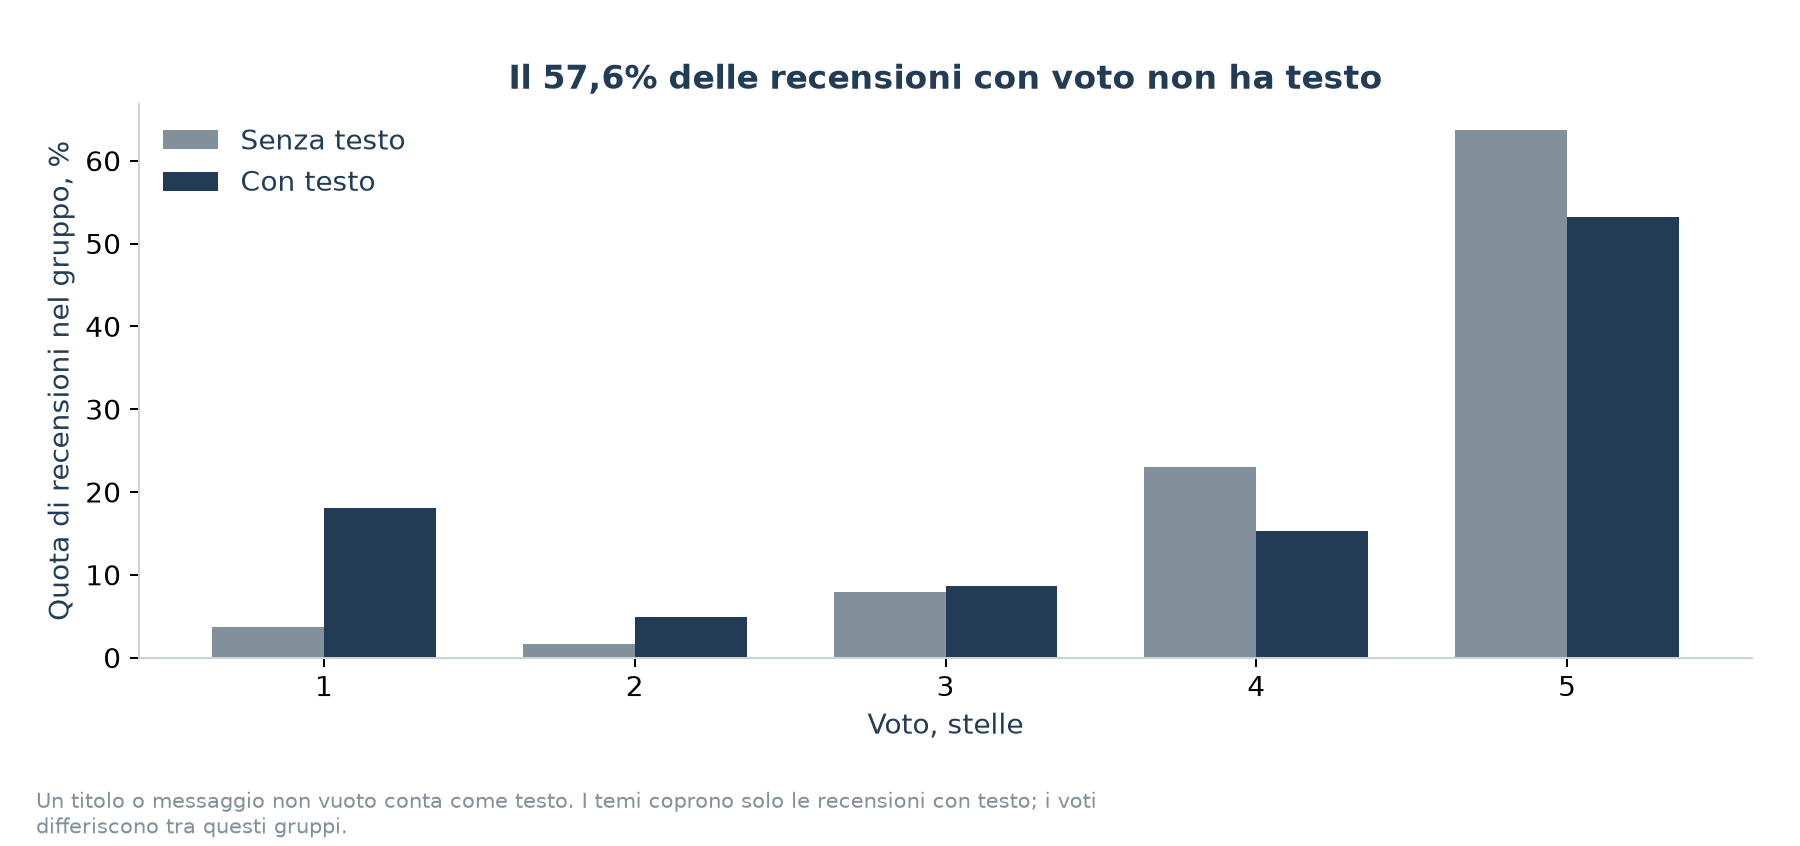

In [3]:
display(Image(filename=str(reports / 'figures/it/text_coverage.png')))

## Effetti grezzi e aggiustati sul voto

Uso ordini a venditore singolo, effetti fissi del venditore e controlli di stato/categoria/prezzo/trasporto. Soglia e pendenza giornaliera sono separate. I gruppi temporali differiscono per gravità; non identifico un costo causale per giorno.

In [4]:
display(pd.read_csv(reports / 'rating_comparison.csv'))
for filename in ['rating_coefficients.csv', 'rating_before_delivery.csv', 'rating_after_delivery.csv', 'rating_after_response.csv']:
    display(pd.read_csv(reports / filename))

,sample,reviews,sellers,on_time_rating,late_rating,raw_difference,threshold,first_day,first_day_low,first_day_high,day_1_7,r_squared
0,all,58743,2000,4.285906,2.254535,-2.031371,-0.504385,-0.800034,-0.911672,-0.688395,-0.295649,0.228814
1,survey_before,4311,954,4.215190,1.949810,-2.265380,-1.090788,-1.294183,-1.509304,-1.079062,-0.203395,0.576592
2,survey_after,54432,1949,4.287773,3.761986,-0.525787,-0.698537,-0.560734,-0.688417,-0.433051,0.137803,0.088530
3,response_after,56065,1965,4.287052,3.675263,-0.611789,-0.548620,-0.542420,-0.649425,-0.435414,0.006200,0.091154


,term,coefficient,low,high
0,late,-0.504385,-0.637349,-0.371421
1,day_1_7,-0.295649,-0.321840,-0.269457
2,day_8_14,0.003547,-0.020052,0.027146
3,day_15_30,0.012459,-0.001278,0.026197


,term,coefficient,low,high
0,late,-1.090788,-1.341637,-0.839940
1,day_1_7,-0.203395,-0.245267,-0.161522
2,day_8_14,-0.010769,-0.036572,0.015034
3,day_15_30,0.017754,0.002144,0.033364


,term,coefficient,low,high
0,late,-0.698537,-0.903282,-0.493792
1,day_1_7,0.137803,0.034169,0.241437
2,day_8_14,-1.618193,-2.180477,-1.055909
3,day_15_30,NaN,NaN,NaN


,term,coefficient,low,high
0,late,-0.548620,-0.694672,-0.402567
1,day_1_7,0.006200,-0.046545,0.058945
2,day_8_14,-0.168216,-0.326040,-0.010392
3,day_15_30,-0.010686,-0.155764,0.134391


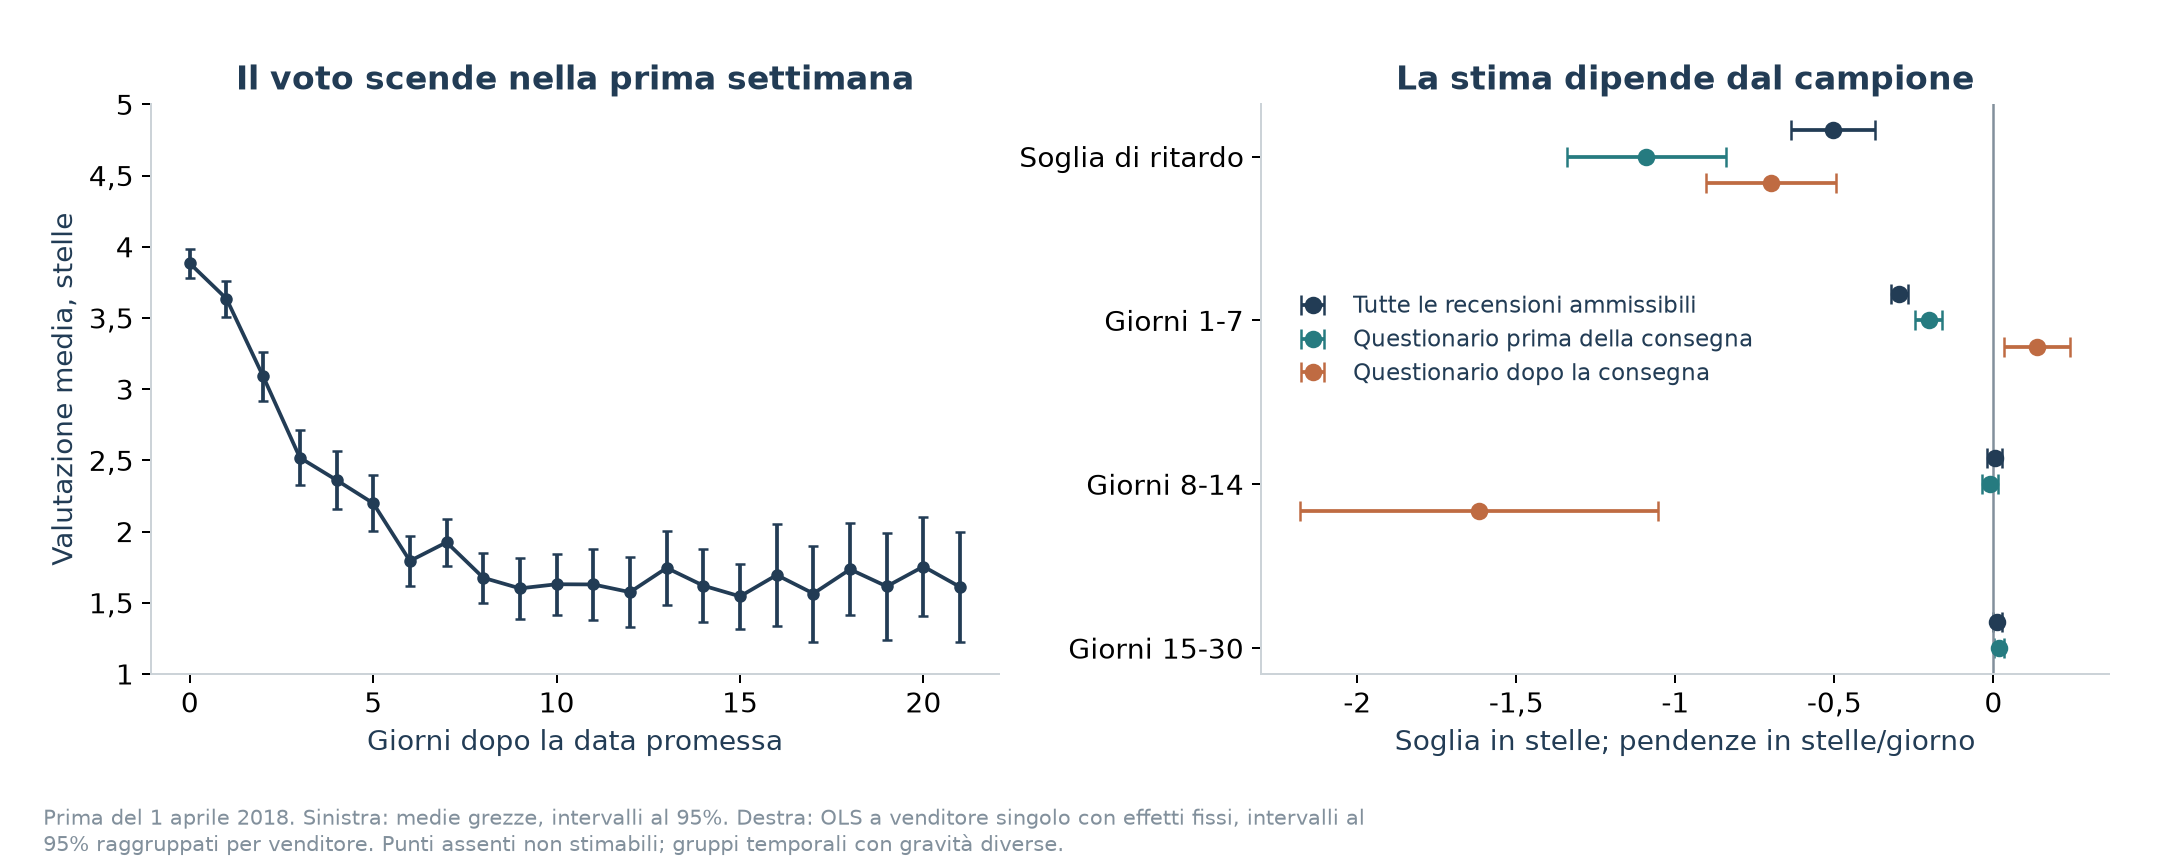

In [5]:
display(Image(filename=str(reports / 'figures/it/delay_effect.png')))

## Variabili al checkout e test temporale

Espando lo storico usando solo acquisti strettamente precedenti con consegna già osservabile. Gli snapshot di catalogo e promessa sono ipotesi. Seleziono i modelli nella validazione gennaio-marzo e testo sugli acquisti aprile-luglio.

In [6]:
display(pd.DataFrame({'feature': FEATURES}))
display(pd.DataFrame([summary['splits']]))
display(pd.read_csv(reports / 'model_metrics.csv'))

,feature
0,log_price
1,freight_share
2,item_count
3,seller_count
4,weight
5,promised_days
6,purchase_month
7,purchase_weekday
8,purchase_hour
9,same_state


,train,validation,refit,test,train_late_rate,validation_late_rate,test_late_rate,selected
0,41197,16782,60468,25777,0.042843,0.069003,0.039027,Boosting 15


,model,period,orders,late_rate,average_precision,roc_auc,brier,precision_at_10pct,recall_at_10pct,lift_at_10pct
0,Logistic regression,validation,16782,0.069003,0.126690,0.657786,0.065379,0.156045,0.226252,2.261444
1,Boosting 7,validation,16782,0.069003,0.124376,0.639458,0.063181,0.152472,0.221071,2.209655
2,Boosting 15,validation,16782,0.069003,0.140169,0.648081,0.063180,0.177487,0.257340,2.572176
3,Constant,test,25777,0.039027,0.039027,0.500000,0.037929,0.039027,0.100000,1.000000
4,Logistic regression,test,25777,0.039027,0.070485,0.668165,0.050645,0.085337,0.218688,2.186624
5,Boosting 15,test,25777,0.039027,0.087480,0.684770,0.037107,0.101241,0.259443,2.594131


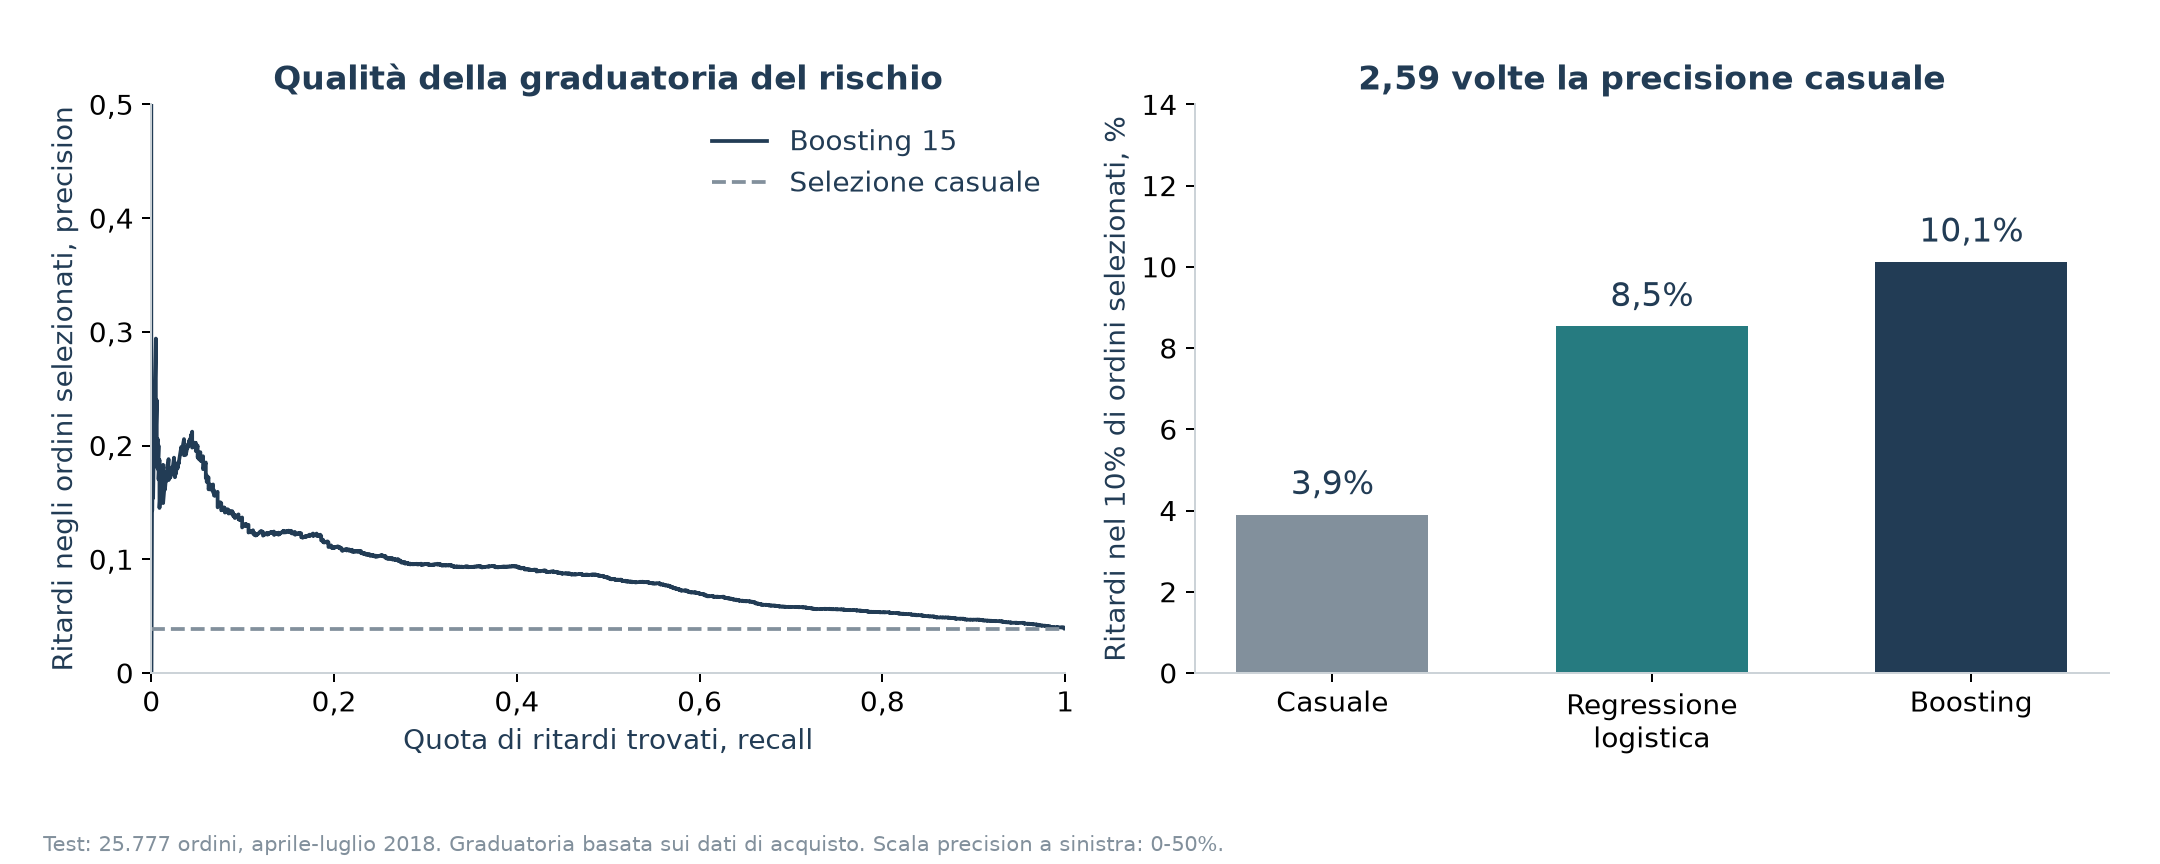

In [7]:
display(Image(filename=str(reports / 'figures/it/risk_validation.png')))

## Riacquisti e finanza

Identifico gli acquirenti con customer_unique_id e richiedo 90 giorni completi dopo consegna e risposta. La differenza osservata è descrittiva. Il beneficio di riacquisto base è zero; nelle ipotesi opzionali conto ciascun acquirente una volta.

In [8]:
repeats = repeat_purchases(frame)
assert repeats['repeat_customers'] == 754
assert repeats['complete_followup_customers'] == 72373
display(pd.DataFrame([repeats]))
display(pd.read_csv(reports / 'repeats_by_lateness.csv'))
source = summary['scenario']
scenario = financial_scenario(source['target_late'], source['affected_orders'], source['gain_sum'], source['all_reviews'], late_customer_counts=source['late_customer_counts'])
assert scenario['net'] == -52817
assert scenario['repeat_margin'] == 0
display(pd.DataFrame([scenario]))

,observation_end_exclusive,horizon_days,identity,eligible_orders,unique_customers,customers_with_multiple_orders,first_reviewed_customers,complete_followup_customers,incomplete_followup_customers,missing_review_answer_customers,...,repeat_customers,repeat_rate,on_time_repeat_rate,late_repeat_rate,descriptive_repeat_rate_gap,customers_with_excluded_pre_anchor_repeats,excluded_pre_anchor_repeat_orders,observed_first_repeat_basket,first_repeat_basket_observations,interpretation
0,2018-09-01 00:00:00,90,customer_unique_id,96470,93350,2801,92747,72373,20374,0,...,754,0.010418,0.010615,0.007825,0.002791,827,867,121.380199,754,Descriptive association in ultimately delivere...


,late,customers,repeat_customers,repeat_rate,mean_index_score
0,0,67261,714,0.010615,4.271465
1,1,5112,40,0.007825,2.163928


,target_late,affected_orders,success,fixed_late,fixed_customers,repeat_uplift,support,compensation,repeat_margin,implementation,net,rating_uplift,break_even_cost
0,565,18359,0.5,282.5,282.25,0.0,1130.0,1130.0,0.0,55077.0,-52817.0,0.016498,0.1231


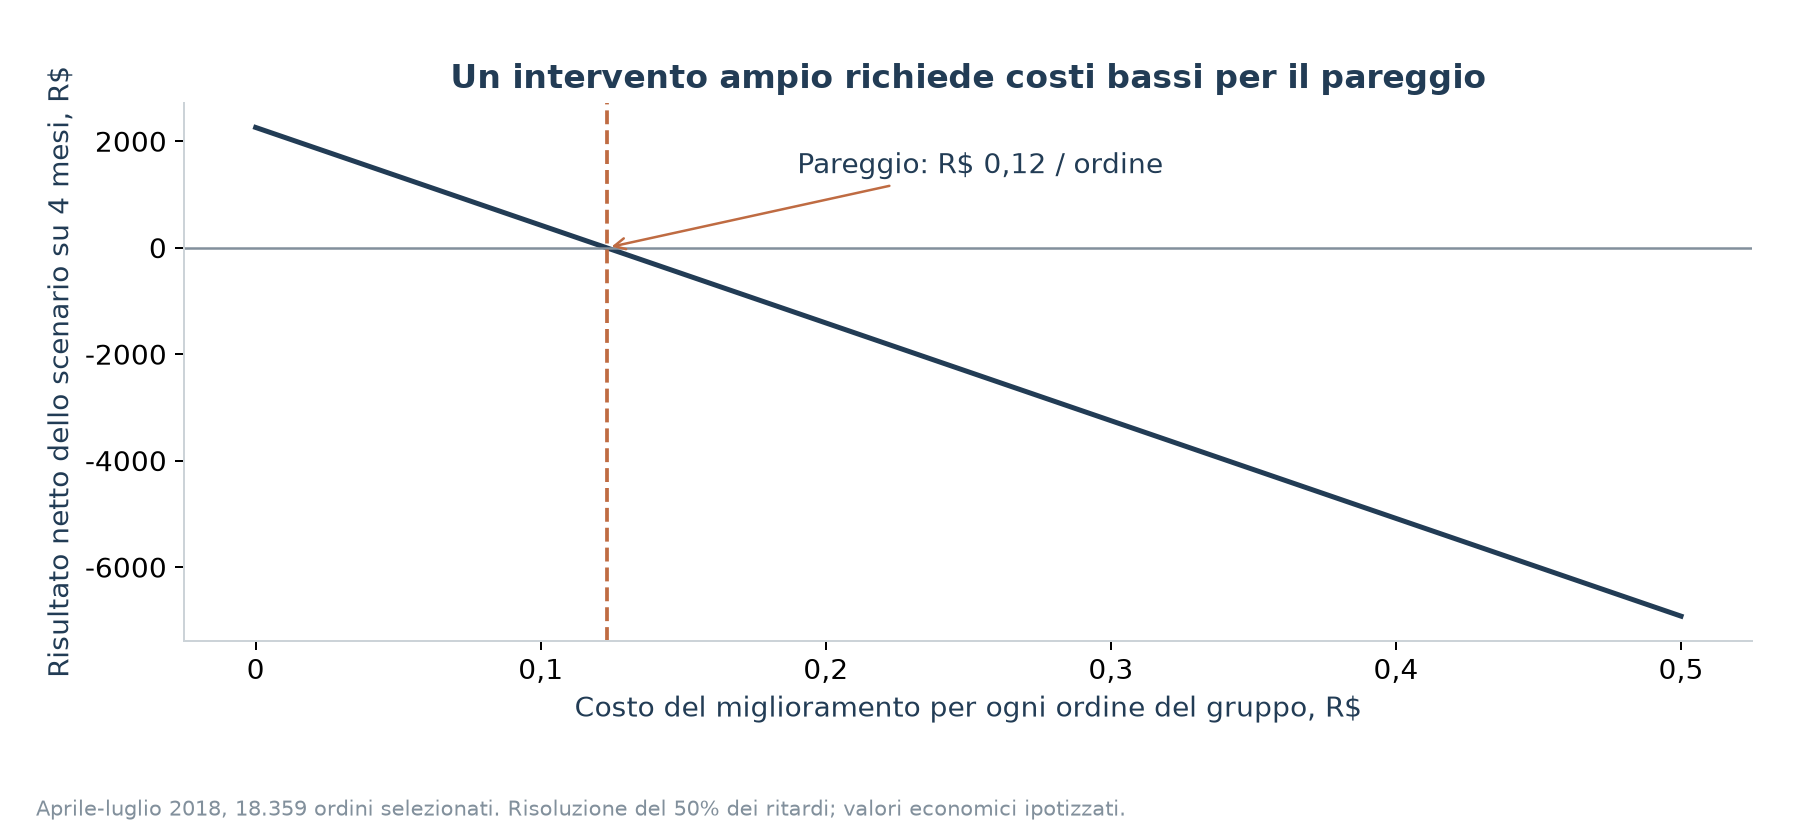

In [9]:
display(Image(filename=str(reports / 'figures/it/financial_sensitivity.png')))

## Confronto finale dei tempi del questionario

Confronto la creazione del questionario allo stesso giorno esatto di ritardo con effetti fissi del venditore. La differenza osservazionale è -1,06 stelle; il confronto più rigoroso per venditore e giorno dà -0,93. La creazione precede la consegna per l’81,6% di tutti gli ordini in ritardo; la risposta scritta per il 68,5%. Modelli esistenti e calcoli finanziari restano invariati. Testerei questionari dopo consegna confermata e notifiche nel decile a rischio più alto in un esperimento 2 × 2 per acquirente. [Disegno completo](../README.it.md#raccomandazione-e-test-ab).

,comparison,orders,sellers,coefficient,low,high
0,creation,1966,631,-1.06,-1.31,-0.82
1,creation_calendar,2246,677,-1.16,-1.45,-0.87
2,creation_same_seller_day,413,69,-0.93,-1.24,-0.62
3,response,2928,775,-1.96,-2.14,-1.78


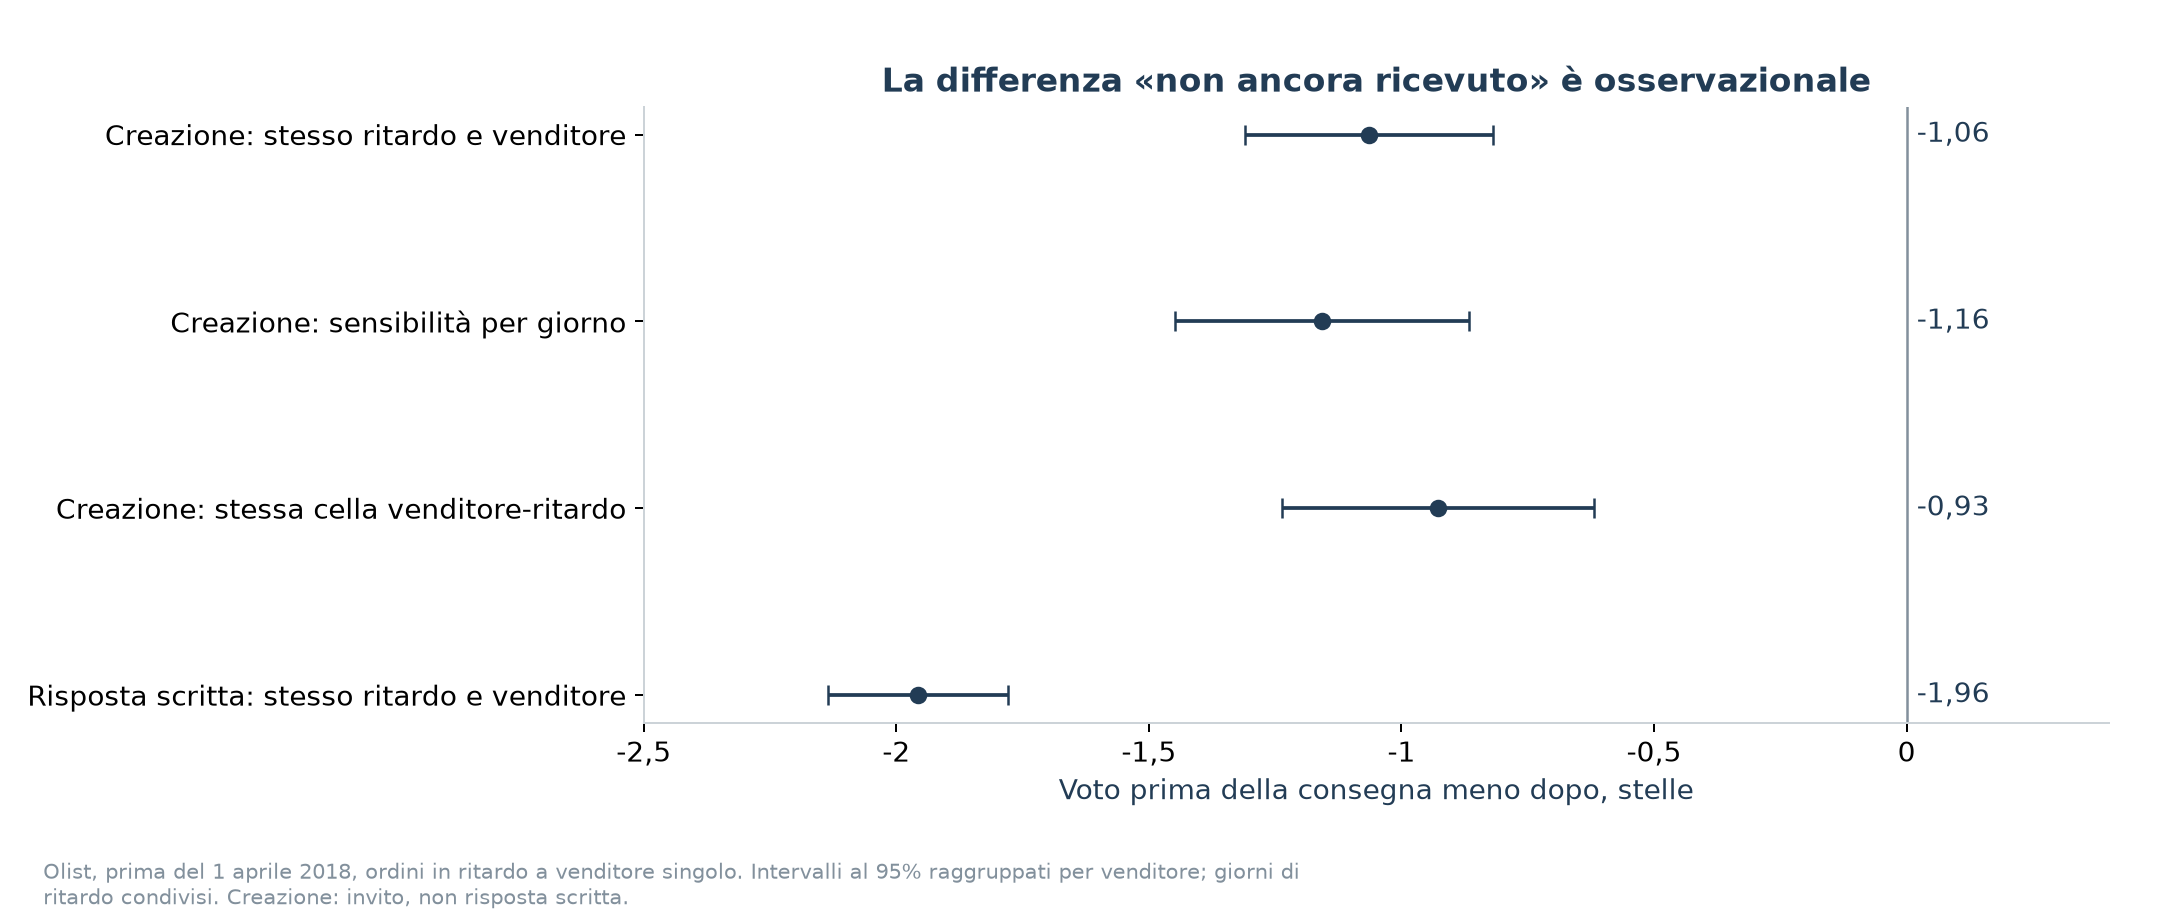

In [10]:
display(pd.read_csv(reports / 'not_received_penalty.csv')[['comparison', 'orders', 'sellers', 'coefficient', 'low', 'high']].round(2))
display(Image(filename=str(reports / 'figures/it/survey_gap.png')))

## Limiti e prossimi passi

Randomizzerei il pilota, misurerei i costi e raccoglierei snapshot al checkout, eventi di corriere/imballaggio e osservazione più lunga dei riacquisti. Le recensioni condivise non identificano il venditore responsabile. Selezione di sole consegne e dati del 2018 limitano la generalizzazione.